# Understanding customer conversion

This notebook follows a customer journey: **view a product → add it to the cart → buy it**.
We measure where visitors stop, compare groups of visitors, and check whether observed
conversion differences are larger than we would expect from random variation.

The intended source is [Retailrocket's e-commerce dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset).
The saved example outputs use **2.7 million synthetic events**. They demonstrate the analysis;
they are not findings about Retailrocket customers. Every chart names the active data source.

**How to use this notebook:** run the cells from top to bottom. Read each explanation, run
the code below it, and inspect the result. The pipeline must already have created its Delta
tables; setup and execution commands are in [README.md](../README.md).

We will:
1. Load the data and define the measures.
2. Calculate KPIs and find funnel drop-off.
3. Compare products and visitor segments.
4. Estimate uncertainty and test conversion differences.
5. Summarize what the results can tell us.

## 1. Load the tools and choose the data

Spark reads and summarizes millions of records. Pandas holds the small result tables,
and Matplotlib draws the charts. Two tested helper functions calculate confidence intervals
and compare conversion rates; their methods are explained in the final reference section.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyspark.sql import Window
from pyspark.sql import functions as F
from statsmodels.stats.multitest import multipletests

from ecommerce_analytics.inference import compare_conversion_groups, conversion_interval
from ecommerce_analytics.spark import local_spark

pd.options.display.float_format = "{:,.2f}".format
plt.style.use("seaborn-v0_8-whitegrid")

The runner selects `retailrocket` or `synthetic`. In an interactive notebook, set
`data_source` explicitly below if needed. Retailrocket is the default; a missing real dataset
produces an error rather than switching to synthetic data.

The setup code finds the repository folder and checks that the selected output exists.
An optional `ECOMMERCE_OUTPUT_PATH` setting supports a different pipeline output folder.

In [2]:
# Find the repository, even when Jupyter starts inside the notebooks folder.
project_root = Path.cwd()
while not (project_root / "pyproject.toml").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Start this notebook inside the repository.")
    project_root = project_root.parent

data_source = os.environ.get("ECOMMERCE_DATA_SOURCE", "retailrocket")
output_folders = {
    "retailrocket": "output/retailrocket",
    "synthetic": "output/synthetic-2700000",
}
if data_source not in output_folders:
    raise ValueError("Choose retailrocket or synthetic as the data source.")

default_folder = project_root / output_folders[data_source]
output_root = Path(os.environ.get("ECOMMERCE_OUTPUT_PATH", str(default_folder))).resolve()
data_label = "Retailrocket events" if data_source == "retailrocket" else "SYNTHETIC DEMONSTRATION"

if not (output_root / "gold/sessions/_delta_log").is_dir():
    raise FileNotFoundError(f"Run the pipeline first. Missing outputs: {output_root}")

display(Markdown(f"**Data used in this run: {data_label}**\n\nFolder: `{output_root}`"))

**Data used in this run: SYNTHETIC DEMONSTRATION**

Folder: `/workspace/Ecommerce-Customer-Behavior-Analytics/output/synthetic-2700000`

## 2. Read the prepared tables

The pipeline has already cleaned the events and assigned them to sessions. We use four
summary tables rather than collecting the entire event dataset into Python memory.

| Table | One row describes |
| --- | --- |
| `sessions` | One visitor session, with event counts and duration |
| `session_products` | One product within one session, with the ordered funnel stages |
| `product_metrics` | One product, with counts across its sessions |
| `daily_funnel` | One date, with session counts and conversion rates |

A **session** groups a visitor's events until a gap exceeds 30 minutes. Exactly 30 minutes
stays in the same session. Dates use UTC.

In [3]:
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
# Hide terminal progress bars so the notebook focuses on analysis results.
spark = local_spark("local[4]", 16, show_progress=False)

sessions = spark.read.format("delta").load(str(output_root / "gold/sessions"))
product_journeys = spark.read.format("delta").load(str(output_root / "gold/session_products"))
product_metrics = spark.read.format("delta").load(str(output_root / "gold/product_metrics"))
daily_funnel = spark.read.format("delta").load(str(output_root / "gold/daily_funnel"))

https://repo.maven.apache.org/maven2 added as a remote repository with the name: repo-1
26/10/14 08:43:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## 3. Define a completed funnel

A completed funnel requires a view, a cart event at or after that view, and a purchase at
or after that cart event, all for the **same product in the same session**. Equal timestamps
are allowed because the source does not provide a reliable order for tied events.

For example, viewing product A and buying product B does not complete product A's funnel.
A purchase without the earlier steps still counts as a purchase, but not as funnel conversion.

We mark each session with three flags: `viewed`, `carted`, and `converted`. A flag is 1 when
at least one product in that session reached the stage, and 0 otherwise. Using the maximum
across product journeys counts the session only once.

In [4]:
session_flags = product_journeys.groupBy("session_id").agg(
    F.max(F.col("first_view").isNotNull().cast("int")).alias("viewed"),
    F.max(F.col("first_cart_after_view").isNotNull().cast("int")).alias("carted"),
    F.max(F.col("first_purchase_after_cart").isNotNull().cast("int")).alias("converted"),
)

session_analysis = sessions.join(session_flags, "session_id", "inner")

# Check that the join kept one row per session and that stages are in order.
assert session_analysis.count() == sessions.count()
assert session_analysis.filter("converted > carted OR carted > viewed").count() == 0

26/10/14 08:43:31 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


We add two simple session groups: the visitor's first observed session or a later session,
and interaction with one product or multiple products. We also record the start day for
the later calendar comparison.

“First observed” does not necessarily mean a new customer: their earlier history may be
outside this dataset. Product breadth is measured during the session, so it describes
behaviour rather than proving that browsing more products increases conversion.

In [5]:
chronological_order = Window.partitionBy("user_id").orderBy("session_start", "session_id")

session_analysis = session_analysis.withColumn(
    "visit_number", F.row_number().over(chronological_order)
)
session_analysis = session_analysis.withColumn(
    "visit_type",
    F.when(F.col("visit_number") == 1, "First observed").otherwise("Returning observed"),
)
session_analysis = session_analysis.withColumn(
    "product_breadth",
    F.when(F.col("unique_products") == 1, "One product").otherwise("Multiple products"),
)

# Spark numbers Sunday as 1; convert this to Monday=0 through Sunday=6.
session_analysis = session_analysis.withColumn(
    "weekday_number", (F.dayofweek("session_start") + 5) % 7
).persist()

## 4. Calculate the KPI scorecard

A **KPI** is a measure used to track performance. Counts show the scale of activity;
rates show how often something happens among the people or sessions eligible for it.

| KPI | Calculation |
| --- | --- |
| Any-purchase session rate | Sessions with any purchase ÷ all sessions |
| Ordered funnel conversion | Completed funnels ÷ sessions with a view |
| View-to-cart rate | Sessions reaching cart after view ÷ viewed sessions |
| Cart-to-purchase rate | Completed funnels ÷ sessions reaching cart after view |
| Cart abandonment rate | Carted sessions without a completed funnel ÷ carted sessions |
| Single-event session rate | Sessions containing one event ÷ all sessions |
| Returning visitor share | Visitors with two or more observed sessions ÷ all visitors |

Example: if 100 sessions viewed a product, 30 reached cart, and 12 completed the funnel,
view-to-cart is 30%, cart-to-purchase is 40%, and overall funnel conversion is 12%.
The cart abandonment rate is 60%.

First, Spark calculates the totals. Summing the 0/1 flags counts sessions reaching a stage.
`.first().asDict()` brings back just one summary row, not all the sessions.

In [6]:
totals = (
    session_analysis.agg(
        F.count("*").alias("sessions"),
        F.countDistinct("user_id").alias("visitors"),
        F.sum("event_count").alias("events"),
        F.sum("viewed").alias("viewed"),
        F.sum("carted").alias("carted"),
        F.sum("converted").alias("converted"),
        F.sum((F.col("purchases") > 0).cast("int")).alias("any_purchase_sessions"),
        F.sum((F.col("event_count") == 1).cast("int")).alias("single_event_sessions"),
        F.avg("event_count").alias("mean_events"),
        F.avg("duration_seconds").alias("mean_duration"),
        F.percentile_approx("duration_seconds", 0.5).alias("median_duration"),
    )
    .first()
    .asDict()
)

visitor_visits = sessions.groupBy("user_id").count()
returning_visitors = visitor_visits.filter(F.col("count") >= 2).count()

activity_counts = pd.DataFrame(
    {
        "Measure": ["Active visitors", "Sessions", "Clean events"],
        "Count": [totals["visitors"], totals["sessions"], totals["events"]],
    }
)
display(activity_counts)

,Measure,Count
0,Active visitors,100000
1,Sessions,1810659
2,Clean events,2700000


Each rate below shows its numerator and denominator so you can see exactly what is being
compared. Rates are displayed as **percentages**. `NaN` means there was no eligible
denominator; it does not mean the rate was 0%.

Single-event sessions are a simple bounce proxy, not a browser analytics bounce definition.
Anonymous visitor IDs identify observed visitors, not verified customer accounts.

In [7]:
kpi_rates = pd.DataFrame(
    [
        ("Any-purchase session rate", totals["any_purchase_sessions"], totals["sessions"]),
        ("Ordered funnel conversion", totals["converted"], totals["viewed"]),
        ("View-to-cart rate", totals["carted"], totals["viewed"]),
        ("Cart-to-purchase rate", totals["converted"], totals["carted"]),
        ("Cart abandonment rate", totals["carted"] - totals["converted"], totals["carted"]),
        ("Single-event session rate", totals["single_event_sessions"], totals["sessions"]),
        ("Returning visitor share", returning_visitors, totals["visitors"]),
    ],
    columns=["KPI", "Numerator", "Denominator"],
)

# Replace zero denominators with NaN to avoid reporting a false 0% rate.
kpi_rates["Rate (%)"] = 100 * kpi_rates["Numerator"] / kpi_rates["Denominator"].replace(0, np.nan)
display(Markdown(f"### KPI rates — {data_label}"))
display(kpi_rates)

engagement = pd.DataFrame(
    {
        "Measure": ["Average events per session", "Average duration (s)", "Median duration (s)"],
        "Value": [totals["mean_events"], totals["mean_duration"], totals["median_duration"]],
    }
)
display(engagement)

### KPI rates — SYNTHETIC DEMONSTRATION

,KPI,Numerator,Denominator,Rate (%)
0,Any-purchase session rate,253894,1810659,14.02
1,Ordered funnel conversion,253894,1810659,14.02
2,View-to-cart rate,635447,1810659,35.09
3,Cart-to-purchase rate,253894,635447,39.96
4,Cart abandonment rate,381553,635447,60.04
5,Single-event session rate,1175212,1810659,64.91
6,Returning visitor share,100000,100000,100.00


,Measure,Value
0,Average events per session,1.49
1,Average duration (s),29.47
2,Median duration (s),0.00


## 5. Find where sessions drop out

For each transition, **lost sessions = starting sessions − progressing sessions**.
Drop-off percentage is the loss divided by the starting count.

Look at both columns: a high percentage shows an inefficient step, while a large count
shows where the most journeys are lost. Drop-off alone does not explain why visitors left.

,Transition,Starting sessions,Progressing sessions,Lost sessions,Drop-off (%)
0,View → cart,1810659,635447,1175212,64.91
1,Cart → purchase,635447,253894,381553,60.04


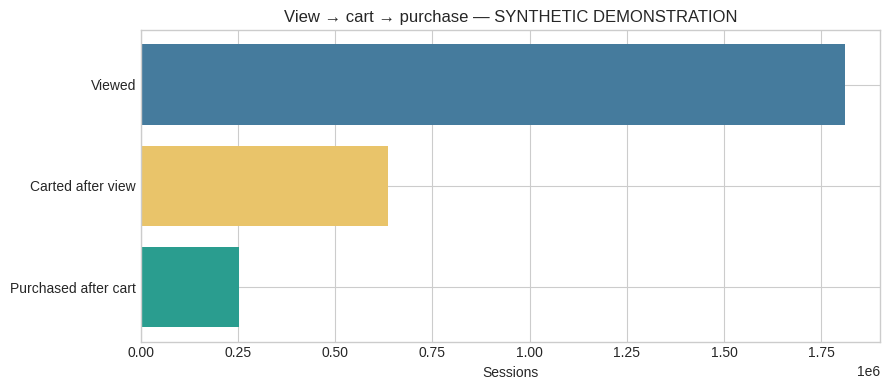

In [8]:
funnel = pd.DataFrame(
    {
        "Stage": ["Viewed", "Carted after view", "Purchased after cart"],
        "Sessions": [totals["viewed"], totals["carted"], totals["converted"]],
    }
)
dropoff = pd.DataFrame(
    [
        ("View → cart", totals["viewed"], totals["carted"]),
        ("Cart → purchase", totals["carted"], totals["converted"]),
    ],
    columns=["Transition", "Starting sessions", "Progressing sessions"],
)

dropoff["Lost sessions"] = dropoff["Starting sessions"] - dropoff["Progressing sessions"]
dropoff["Drop-off (%)"] = (
    100 * dropoff["Lost sessions"] / dropoff["Starting sessions"].replace(0, np.nan)
)
display(dropoff)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(funnel["Stage"], funnel["Sessions"], color=["#457b9d", "#e9c46a", "#2a9d8f"])
ax.invert_yaxis()
ax.set(xlabel="Sessions", title=f"View → cart → purchase — {data_label}")
plt.tight_layout()
plt.show()

## 6. Follow conversion over time

The top chart shows daily activity; the bottom shows the share of viewed sessions that
completed the funnel. A drop in purchases can come from fewer visitors, a lower conversion
rate, or both, so inspect the two charts together.

The pipeline assigns each journey to its session start date, even when it crosses midnight.
These daily charts describe observed sessions; repeat visitors mean the sessions are not
independent samples for statistical testing.

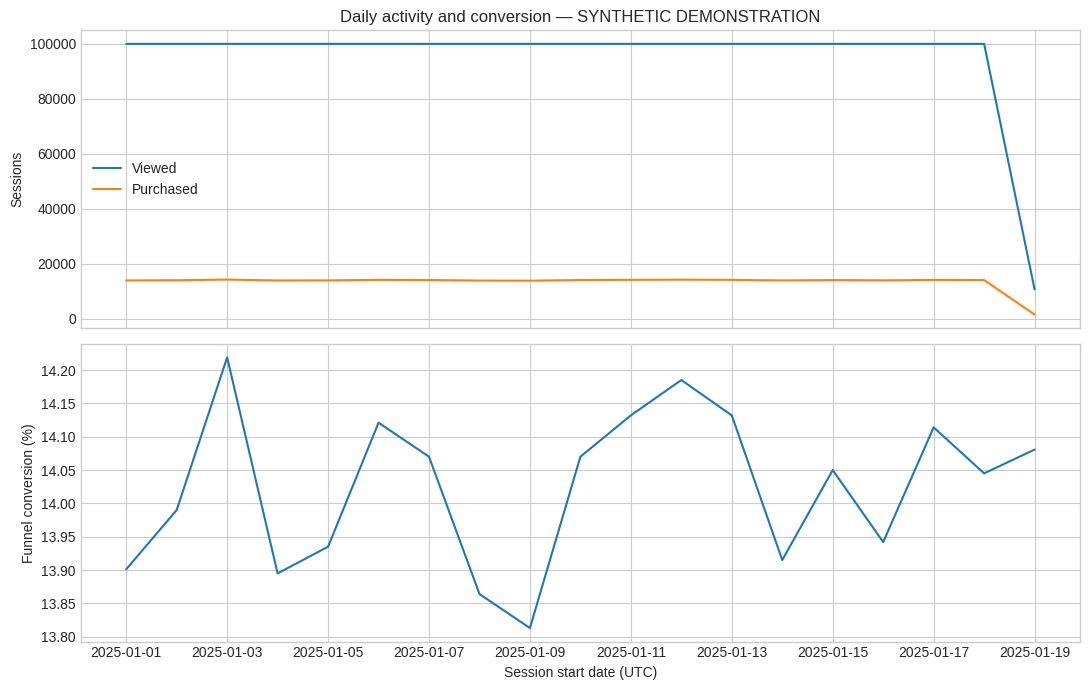

In [9]:
daily_results = daily_funnel.orderBy("session_date").toPandas()
daily_results["session_date"] = pd.to_datetime(daily_results["session_date"])
daily_results["conversion_pct"] = 100 * pd.to_numeric(
    daily_results["view_to_purchase_rate"], errors="coerce"
)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(daily_results["session_date"], daily_results["viewed_sessions"], label="Viewed")
axes[0].plot(daily_results["session_date"], daily_results["purchased_sessions"], label="Purchased")
axes[0].set(ylabel="Sessions", title=f"Daily activity and conversion — {data_label}")
axes[0].legend()
axes[1].plot(daily_results["session_date"], daily_results["conversion_pct"])
axes[1].set(xlabel="Session start date (UTC)", ylabel="Funnel conversion (%)")
plt.tight_layout()
plt.show()

## 7. Identify products with high cart-loss volume

We count carted product journeys that did not complete a purchase. One session may appear
for several products, so these counts are **session/product pairs**, not unique visitors.

We show the 15 products with the largest loss, requiring at least 30 viewed journeys.
This small-volume filter keeps tiny samples out of the ranking; it is not a significance
test. The ranking is a starting point for investigation, not proof of a product problem.

,product_id,viewed_sessions,carted_sessions,converted_sessions,lost_carts,conversion_pct
0,4698,392,162,53,109,13.52
1,1914,427,165,58,107,13.58
2,1571,392,150,44,106,11.22
3,2068,368,158,53,105,14.40
4,4824,362,149,44,105,12.15
5,1475,362,150,46,104,12.71
6,2107,389,144,40,104,10.28
7,996,383,152,48,104,12.53
8,2862,401,156,53,103,13.22
9,3334,385,141,38,103,9.87


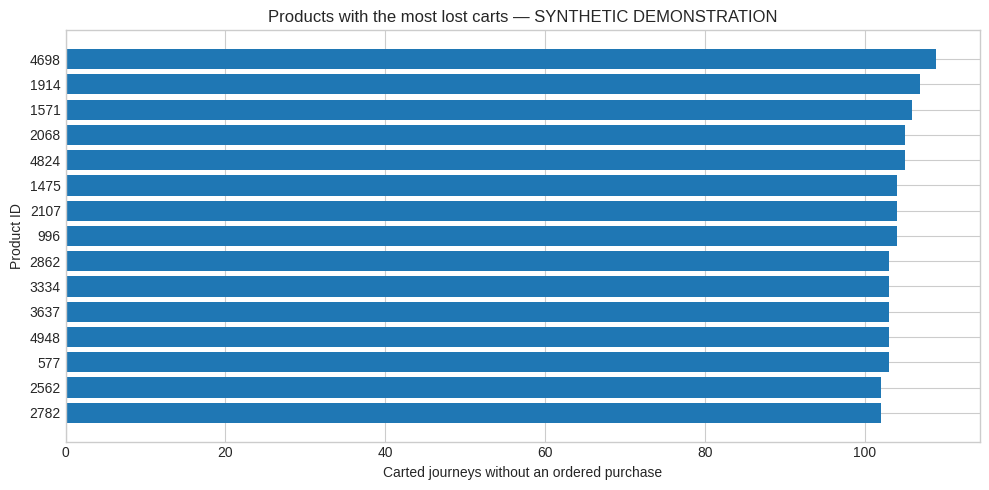

In [10]:
minimum_product_views = 30
product_results = (
    product_metrics.filter(F.col("viewed_sessions") >= minimum_product_views)
    .withColumn("lost_carts", F.col("carted_sessions") - F.col("converted_sessions"))
    .withColumn("conversion_pct", 100 * F.col("converted_sessions") / F.col("viewed_sessions"))
    .orderBy(F.desc("lost_carts"), "product_id")
    .limit(15)
    .toPandas()
)
display(
    product_results[
        [
            "product_id",
            "viewed_sessions",
            "carted_sessions",
            "converted_sessions",
            "lost_carts",
            "conversion_pct",
        ]
    ]
)

if product_results.empty:
    print("No products meet the minimum-view threshold in this dataset.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(product_results["product_id"].astype(str), product_results["lost_carts"])
    ax.invert_yaxis()
    ax.set(
        xlabel="Carted journeys without an ordered purchase",
        ylabel="Product ID",
        title=f"Products with the most lost carts — {data_label}",
    )
    plt.tight_layout()
    plt.show()

## 8. Compare visitor segments

**Segmentation** means dividing the data into groups so that overall averages do not hide
different patterns. Here we compare first observed versus returning sessions and sessions
involving one versus multiple products.

Read the group size beside its rate. A high conversion percentage in a small group may
matter less to the business than a modest improvement in a large group. These comparisons
describe behaviour; they do not establish that a segment characteristic causes a purchase.

,visit_type,product_breadth,sessions,viewed_sessions,carted_sessions,converted_sessions,average_events,conversion_pct,cart_abandonment_pct
0,First observed,One product,100000,100000,35230,13902,1.49,13.90,60.54
1,Returning observed,One product,1710659,1710659,600217,239992,1.49,14.03,60.02


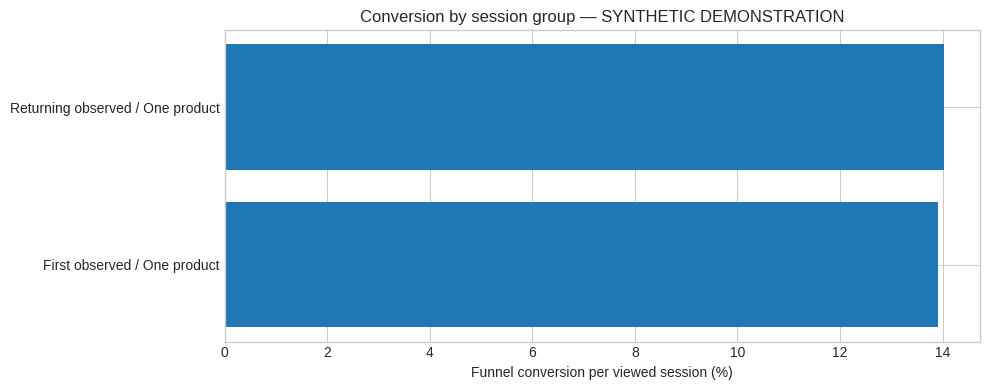

In [11]:
segment_results = (
    session_analysis.groupBy("visit_type", "product_breadth")
    .agg(
        F.count("*").alias("sessions"),
        F.sum("viewed").alias("viewed_sessions"),
        F.sum("carted").alias("carted_sessions"),
        F.sum("converted").alias("converted_sessions"),
        F.avg("event_count").alias("average_events"),
    )
    .orderBy("visit_type", "product_breadth")
    .toPandas()
)

segment_results["conversion_pct"] = (
    100
    * segment_results["converted_sessions"]
    / segment_results["viewed_sessions"].replace(0, np.nan)
)
segment_results["cart_abandonment_pct"] = (
    100
    * (segment_results["carted_sessions"] - segment_results["converted_sessions"])
    / segment_results["carted_sessions"].replace(0, np.nan)
)
display(segment_results)

segment_labels = segment_results["visit_type"] + " / " + segment_results["product_breadth"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(segment_labels, segment_results["conversion_pct"])
ax.set(
    xlabel="Funnel conversion per viewed session (%)",
    title=f"Conversion by session group — {data_label}",
)
plt.tight_layout()
plt.show()

## 9. Prepare one observation per visitor for testing

The charts above use all sessions. For the statistical comparison, repeatedly counting one
visitor's sessions as independent observations could make the evidence look stronger than
it is. We instead select **one viewed session per visitor**.

A fixed hash of session ID and seed 42 gives a repeatable selection across the observed
period. The rule does not look at whether the visitor purchased. We do not select whichever
session makes a comparison look more favourable. Anonymous visitor IDs are still an
approximation: one person can have several IDs, or an ID can be shared.

The code sorts each visitor's eligible sessions by that fixed hash and keeps the first.

In [12]:
sampling_order = Window.partitionBy("user_id").orderBy(
    F.xxhash64("session_id", F.lit(42)), "session_id"
)
viewed_sessions = session_analysis.filter(F.col("viewed") == 1)
visitor_sample = viewed_sessions.withColumn("sample_rank", F.row_number().over(sampling_order))
visitor_sample = visitor_sample.filter(F.col("sample_rank") == 1)

day_results = (
    visitor_sample.groupBy("weekday_number")
    .agg(
        F.count("*").alias("visitors"),
        F.sum("converted").alias("converted_visitors"),
    )
    .toPandas()
)

# Keep all seven days visible, including days with no visitors.
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_results = day_results.set_index("weekday_number").reindex(range(7), fill_value=0).reset_index()
day_results["day"] = day_names
day_results["visitors"] = day_results["visitors"].astype(int)
day_results["converted_visitors"] = day_results["converted_visitors"].astype(int)

### Show conversion with an uncertainty interval

The observed rate is an estimate. A **95% confidence interval** summarizes its sampling
uncertainty under the model assumptions. Smaller groups usually produce wider intervals.
An interval is not a guarantee about an individual visitor's chance of buying.

The helper takes a converted count and a total count and returns Wilson interval bounds
as fractions. We multiply by 100 to display percentages. Days with no visitors have no
rate or interval.

,day,visitors,converted_visitors,conversion_pct,ci_lower_pct,ci_upper_pct
0,Monday,10969,1477,13.47,12.84,14.12
1,Tuesday,10967,1518,13.84,13.21,14.50
2,Wednesday,16651,2344,14.08,13.56,14.61
3,Thursday,16573,2262,13.65,13.13,14.18
4,Friday,16620,2370,14.26,13.74,14.80
5,Saturday,16522,2271,13.75,13.23,14.28
6,Sunday,11698,1662,14.21,13.59,14.85


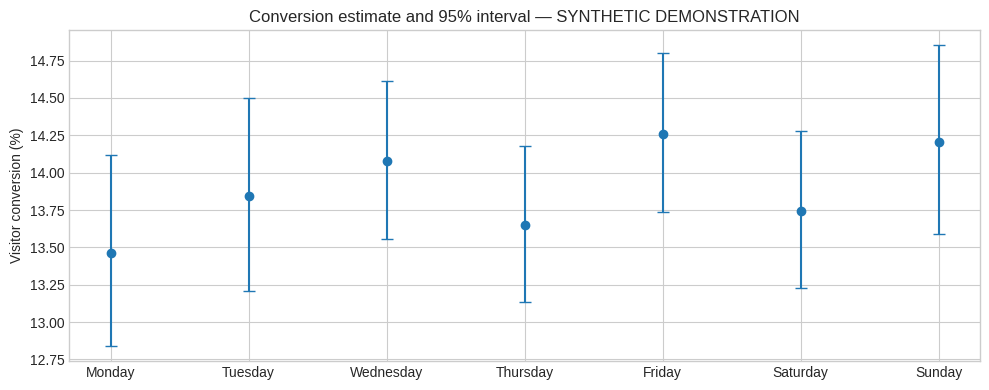

In [13]:
day_results["conversion_pct"] = (
    100 * day_results["converted_visitors"] / day_results["visitors"].replace(0, np.nan)
)
confidence_limits = []
for day in day_results.itertuples():
    lower, upper = conversion_interval(day.converted_visitors, day.visitors)
    confidence_limits.append({"ci_lower_pct": 100 * lower, "ci_upper_pct": 100 * upper})
day_results = pd.concat([day_results, pd.DataFrame(confidence_limits)], axis=1)
display(
    day_results[
        ["day", "visitors", "converted_visitors", "conversion_pct", "ci_lower_pct", "ci_upper_pct"]
    ]
)

days_with_data = day_results[day_results["visitors"] > 0]
lower_error = days_with_data["conversion_pct"] - days_with_data["ci_lower_pct"]
upper_error = days_with_data["ci_upper_pct"] - days_with_data["conversion_pct"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(
    days_with_data["day"],
    days_with_data["conversion_pct"],
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=4,
)
ax.set(
    ylabel="Visitor conversion (%)", title=f"Conversion estimate and 95% interval — {data_label}"
)
plt.tight_layout()
plt.show()

## 10. Test the weekend–weekday conversion difference

We specify the comparison before looking at its result:
- **Null hypothesis:** weekend and weekday visitors have the same conversion probability.
- **Alternative hypothesis:** those probabilities differ, in either direction.
- **Decision rule:** flag evidence of a difference when the two-sided p-value is below 0.05.

The p-value describes how surprising the counts would be under the equal-rate hypothesis,
given the test's assumptions. It is **not** the probability that the null hypothesis is true.
The helper uses chi-square for sufficiently large expected counts and Fisher's exact test
for sparse counts. It leaves the comparison untested if either group has no visitors.

This is an observational calendar comparison, not a randomized A/B test: product mix and
visitor mix could explain a difference. We report its size and uncertainty alongside the
p-value so that a statistical decision does not replace business judgement.

In [14]:
count_columns = ["visitors", "converted_visitors"]
weekday_counts = day_results.loc[day_results["weekday_number"] < 5, count_columns].sum()
weekend_counts = day_results.loc[day_results["weekday_number"] >= 5, count_columns].sum()

timing_test = compare_conversion_groups(
    int(weekday_counts["converted_visitors"]),
    int(weekday_counts["visitors"]),
    int(weekend_counts["converted_visitors"]),
    int(weekend_counts["visitors"]),
)


def format_p_value(value):
    # Significant figures keep very small p-values from appearing as zero.
    return "Not tested" if pd.isna(value) else f"{value:.4g}"


timing_summary = pd.DataFrame(
    [
        {
            "Comparison": "Weekend minus weekday",
            "Method": timing_test["method"],
            "Weekday visitors": int(weekday_counts["visitors"]),
            "Weekend visitors": int(weekend_counts["visitors"]),
            "Weekday conversion (%)": 100 * timing_test["rate_a"],
            "Weekend conversion (%)": 100 * timing_test["rate_b"],
            "Difference (percentage points)": 100 * timing_test["difference"],
            "95% lower (percentage points)": 100 * timing_test["ci_low"],
            "95% upper (percentage points)": 100 * timing_test["ci_high"],
            "p-value": format_p_value(timing_test["p_value"]),
        }
    ]
)
display(timing_summary.T.rename(columns={0: "Result"}))

,Result
Comparison,Weekend minus weekday
Method,Pearson chi-square
Weekday visitors,71780
Weekend visitors,28220
Weekday conversion (%),13.89
Weekend conversion (%),13.94
Difference (percentage points),0.05
95% lower (percentage points),-0.43
95% upper (percentage points),0.53
p-value,0.8503


### Read the result in plain language

A difference from 10% to 12% is **2 percentage points**, not 2%. A confidence interval
crossing zero includes differences in either direction. A large p-value means we lack
evidence of a difference under this test; it does not prove the groups are equivalent.
A small p-value does not show that weekend timing caused conversion to change.

In [15]:
if timing_test["status"] != "tested":
    conclusion = "The test could not run because one group has no eligible visitors."
elif timing_test["p_value"] < 0.05:
    conclusion = "The test provides evidence of a conversion difference at the 0.05 threshold."
else:
    conclusion = (
        "The test does not provide evidence of a conversion difference at the 0.05 threshold."
    )

display(Markdown(f"**{data_label}:** {conclusion}"))

**SYNTHETIC DEMONSTRATION:** The test does not provide evidence of a conversion difference at the 0.05 threshold.

## 11. Optional: explore individual weekdays

We also compare Tuesday through Sunday with Monday. Six tests provide more opportunities
for a chance finding than one test, so we use **Holm correction** to adjust their p-values.
Interpret the adjusted p-values, not just the smallest raw p-value.

Missing groups remain untested. For the six planned comparisons, they contribute a value
of 1 to the correction calculation but are displayed as “Not tested.” These follow-up
comparisons use the same data as the main test; they are not independent confirmation.

In [16]:
monday_counts = day_results.iloc[0]
day_comparisons = []

for day in day_results.iloc[1:].itertuples():
    result = compare_conversion_groups(
        int(monday_counts["converted_visitors"]),
        int(monday_counts["visitors"]),
        day.converted_visitors,
        day.visitors,
    )
    day_comparisons.append({"comparison": f"{day.day} minus Monday", **result})

weekday_tests = pd.DataFrame(day_comparisons)
planned_p_values = weekday_tests["p_value"].fillna(1.0)
_, adjusted_p_values, _, _ = multipletests(planned_p_values, alpha=0.05, method="holm")
tested = weekday_tests["status"] == "tested"
weekday_tests["adjusted_p_value"] = np.where(tested, adjusted_p_values, np.nan)
weekday_tests["evidence_after_correction"] = tested & (adjusted_p_values < 0.05)

weekday_report = pd.DataFrame(
    {
        "Comparison": weekday_tests["comparison"],
        "Status": weekday_tests["status"],
        "Difference (percentage points)": 100 * weekday_tests["difference"],
        "Raw p-value": weekday_tests["p_value"].map(format_p_value),
        "Adjusted p-value": weekday_tests["adjusted_p_value"].map(format_p_value),
        "Evidence after correction": weekday_tests["evidence_after_correction"],
    }
)
display(weekday_report)

,Comparison,Status,Difference (percentage points),Raw p-value,Adjusted p-value,Evidence after correction
0,Tuesday minus Monday,tested,0.38,0.417,1,False
1,Wednesday minus Monday,tested,0.61,0.1494,0.5978,False
2,Thursday minus Monday,tested,0.18,0.6634,1,False
3,Friday minus Monday,tested,0.79,0.0622,0.3732,False
4,Saturday minus Monday,tested,0.28,0.5075,1,False
5,Sunday minus Monday,tested,0.74,0.1059,0.5294,False


## 12. Summarize the findings and choose the next investigation

The summary below uses the active dataset's results. Treat the synthetic example as a
demonstration of the calculations, not as a recommendation for a real business.

Start with large loss volumes, inspect tracking and product context, and look for patterns
that also appear in another time period. A lost journey might reflect missing tracking or
a later purchase outside the session, rather than an abandoned purchase intent.

In [17]:
eligible_steps = dropoff[dropoff["Starting sessions"] > 0]
if not eligible_steps.empty:
    largest_loss = eligible_steps.sort_values("Lost sessions", ascending=False).iloc[0]
    display(
        Markdown(
            f"**{data_label}:** The largest funnel loss is **{largest_loss['Transition']}**: "
            f"{int(largest_loss['Lost sessions']):,} sessions, or "
            f"{largest_loss['Drop-off (%)']:.2f}% of that step's starting sessions."
        )
    )

if not product_results.empty:
    top_product = product_results.iloc[0]
    display(
        Markdown(
            f"Among products meeting the {minimum_product_views}-view threshold, "
            f"**product {top_product['product_id']}** has the most lost carts: "
            f"{int(top_product['lost_carts']):,} session/product journeys."
        )
    )

display(
    Markdown(
        "**Next investigation:** check tracking and the largest lost journeys; compare product "
        "and visitor mix across groups; validate promising patterns in another time period. "
        "To test a proposed product change, plan a randomized experiment with a worthwhile "
        "effect size and enough visitors to detect it."
    )
)

**SYNTHETIC DEMONSTRATION:** The largest funnel loss is **View → cart**: 1,175,212 sessions, or 64.91% of that step's starting sessions.

Among products meeting the 30-view threshold, **product 4698** has the most lost carts: 109 session/product journeys.

**Next investigation:** check tracking and the largest lost journeys; compare product and visitor mix across groups; validate promising patterns in another time period. To test a proposed product change, plan a randomized experiment with a worthwhile effect size and enough visitors to detect it.

## Reference: methods and limits

| Term | What it means here |
| --- | --- |
| Wilson interval | A 95% interval for a converted count divided by an eligible count |
| Newcombe-Wilson interval | A 95% interval for weekend minus weekday conversion |
| Chi-square test | A two-group rate comparison when every expected cell count is at least 5 |
| Fisher's exact test | The comparison used for sparse or degenerate count tables |
| Holm correction | Adjustment across the six planned weekday comparisons |

The tested formulas are in [inference.py](../src/ecommerce_analytics/inference.py).
The main comparison's interval is not adjusted for the exploratory comparisons.

- One sampled session represents observed behaviour, not a visitor's lifetime.
- Device, campaign, demographic, and usable revenue fields are absent from the event input.
- Calendar differences can reflect visitor or product mix; there is no experiment assignment.
- Product rankings and behavioural segments are descriptive, not significance tests.
- Synthetic timing patterns are artificial and do not establish real business findings.

Re-run every cell after changing the source so that results do not mix datasets. The final
cell releases cached session data and stops the Spark session started by this notebook.

In [18]:
session_analysis.unpersist()
spark.stop()